In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
import warnings 

warnings.simplefilter('ignore')

import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import plotly.io as pio
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd
import plotly.express as px

In [2]:

start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-180  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-1  )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

#data_inicial='2023-01-01'
#data_final='2023-07-25'

In [3]:
Select = f"""
        select * from dl_Gestao_recursos.intraday_bmf
        where dt = (select dt from dl_gestao_recursos.du where dt = CURRENT_DATE()) 
        """

df = pd.read_sql(Select, session)
df_bck = df

In [4]:
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
df.HORA = pd.to_datetime(df.HORA, format='%H:%M:%S').dt.time

In [5]:
df['DT_HORA'] = df.apply(lambda row: datetime.combine(row['DT'], row['HORA']), axis=1)
#df['DT_HORA'] = df['DT_HORA'].apply(lambda x: x.replace(second=0, microsecond=0))

In [6]:
df.DT_HORA = df['DT_HORA'].dt.strftime('%Y-%m-%d %H:%M')

In [7]:
## DF BYUER
df_buy = df.drop(columns=['HORA', 'SELLER'])
df_buy['CORRETORA'] = df_buy['BUYER']
df_buy = df_buy.drop(columns=['BUYER'])
## DF SELLER

df_sell = df.drop(columns=['HORA', 'BUYER'])
df_sell['CORRETORA'] = df_sell['SELLER']
df_sell.TAMANHO = df_sell.TAMANHO*-1             
df_sell = df_sell.drop(columns=['SELLER'])

In [8]:
df_final = []
df_final = pd.concat([df_sell,df_buy], ignore_index=True) 
df_sum= df_final.groupby(['CORRETORA','DT_HORA','FUVCT_FUATV_CD','FUVCT_CD','DT']).sum().reset_index()

In [9]:
from pandasql import sqldf

select = """
SELECT DT, DT_HORA, CORRETORA, FUVCT_FUATV_CD,FUVCT_CD, TAMANHO
, SUM(TAMANHO) OVER (PARTITION BY CORRETORA, FUVCT_FUATV_CD, FUVCT_CD ORDER BY DT_HORA ROWS BETWEEN 80000 PRECEDING AND CURRENT ROW) AS TAMANHO_ACUM
FROM df_sum
--where CORRETORA NOT IN ('AGOR', 'XPIN','LQDZ')
order by FUVCT_CD
"""

resultado = sqldf(select, globals())
display(resultado)

,DT,DT_HORA,CORRETORA,FUVCT_FUATV_CD,FUVCT_CD,TAMANHO,TAMANHO_ACUM
0,2025-02-03 00:00:00.000000,2025-02-03 09:00,AGOR,FUT DI1,F26,591.0,591.0
1,2025-02-03 00:00:00.000000,2025-02-03 09:03,AGOR,FUT DI1,F26,355.0,946.0
2,2025-02-03 00:00:00.000000,2025-02-03 09:04,AGOR,FUT DI1,F26,5001.0,5947.0
3,2025-02-03 00:00:00.000000,2025-02-03 09:05,AGOR,FUT DI1,F26,5770.0,11717.0
4,2025-02-03 00:00:00.000000,2025-02-03 09:06,AGOR,FUT DI1,F26,1.0,11718.0
...,...,...,...,...,...,...,...
33212,2025-02-03 00:00:00.000000,2025-02-03 13:52,TPBZ,FUT DI1,Z25,1000.0,1000.0
33213,2025-02-03 00:00:00.000000,2025-02-03 10:40,UBS,FUT DI1,Z25,2650.0,2650.0
33214,2025-02-03 00:00:00.000000,2025-02-03 10:41,UBS,FUT DI1,Z25,600.0,3250.0
33215,2025-02-03 00:00:00.000000,2025-02-03 10:44,UBS,FUT DI1,Z25,900.0,4150.0


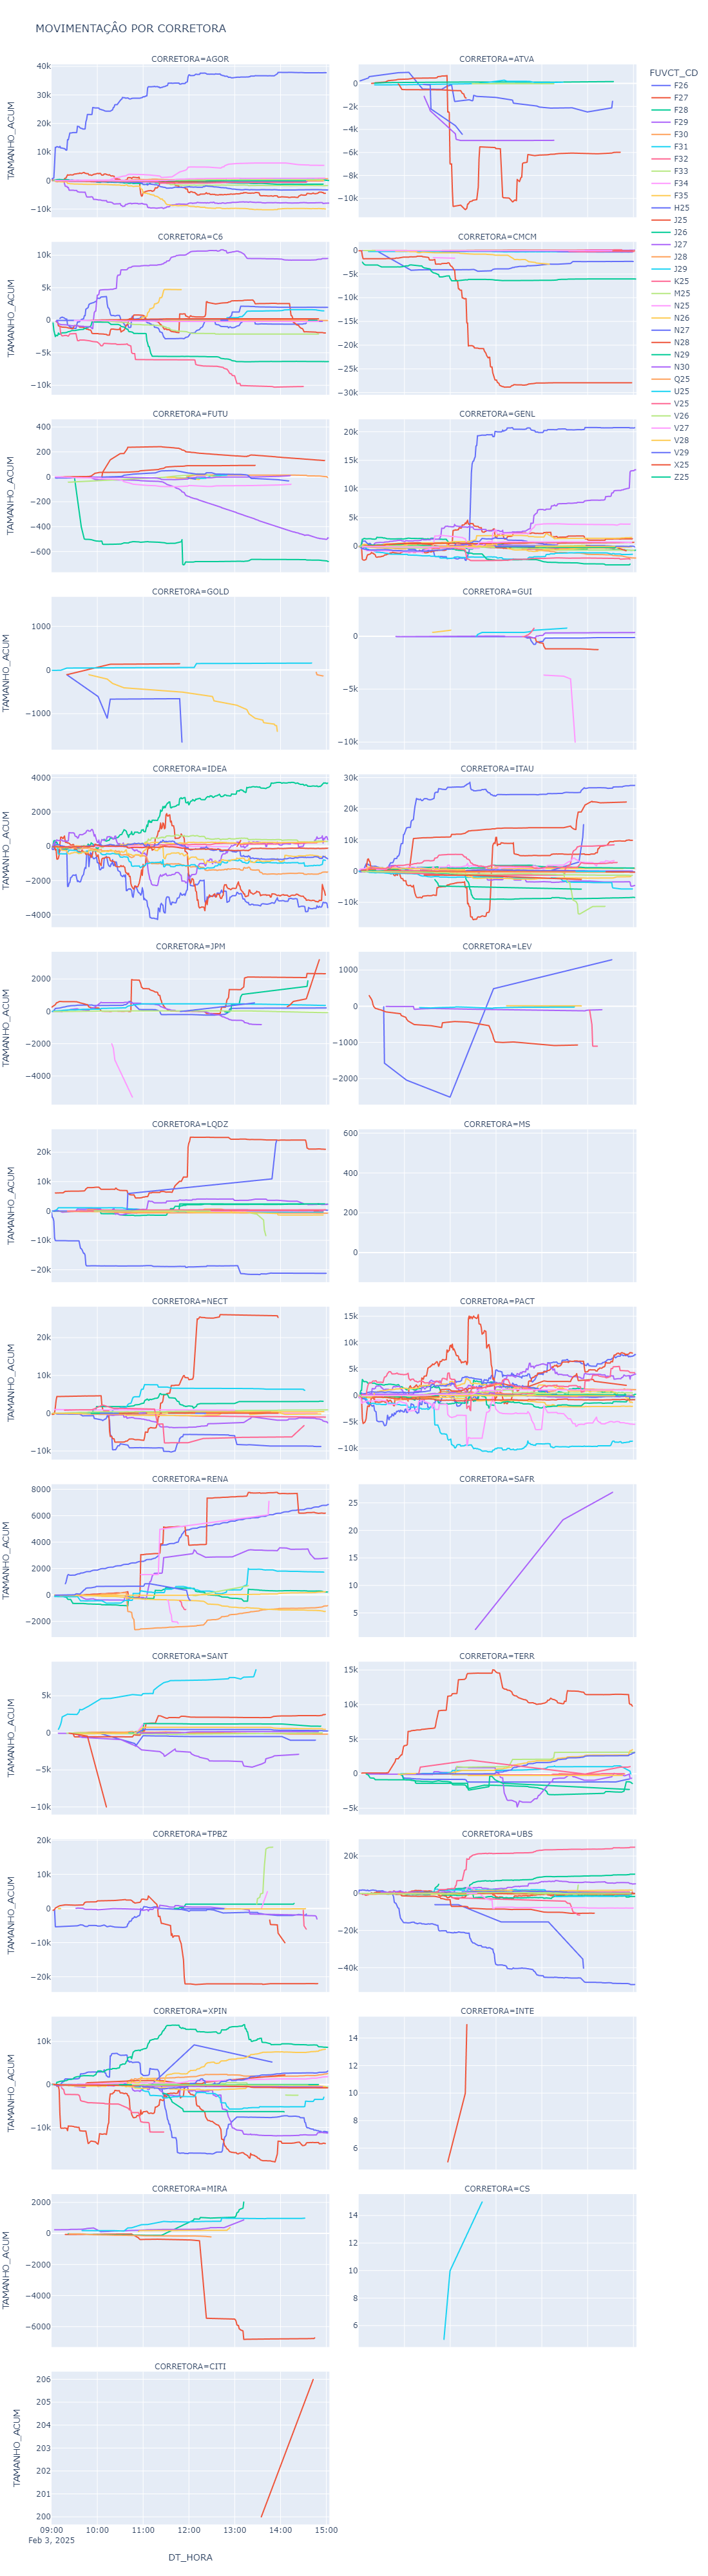

In [10]:
import plotly.express as px
fig = px.line(resultado
               , y='TAMANHO_ACUM'
               , x='DT_HORA'
               #, animation_frame=df_plot_m.date_str
               #, animation_group="group_by"
               #, facet_col_wrap=col_wrap       
               #, facet_col = col
               , facet_col_wrap=2     
               , facet_col = 'CORRETORA'   
               , color='FUVCT_CD'
              #, color_discrete_map=color_map
               , hover_name='CORRETORA'
               #, labels={'value':'Number of Cases','day_number':"Days Since "+ str(threshold) +"th Case",'date':'Date', 'name':'City'}
               #, range_y=[0.1, df_plot_m.value.max()+5000]
               #, range_x = [df_plot_m.date.min(),df_plot_m.date.max()]
               #, text=df_plot_m[group_by]
               #, size=1
               , title='MOVIMENTAÇÂO POR CORRETORA'
               , height=4000
               , width=1000
               , facet_col_spacing=0.05
               , facet_row_spacing=0.01
               )

#fig.update_layout(facet_row_spacing=0.05, facet_col_spacing=0.05)
fig.update_yaxes(matches=None) 
#fig.update_xaxes(matches=None)
fig.update_yaxes(showticklabels=True)

fig.show()

display(HTML("""
<script>
    // Encontrar todas as áreas de saída
    var output_areas = document.querySelectorAll('.output');
    output_areas.forEach(function(output_area) {
        // Remover a classe 'collapsed' para expandir a saída
        output_area.classList.remove('collapsed');
    });
</script>
"""))

In [11]:
!jupyter --version

Selected Jupyter core packages...
IPython          : 8.20.0
ipykernel        : 6.28.0
ipywidgets       : 7.7.2
jupyter_client   : 8.6.0
jupyter_core     : 5.5.0
jupyter_server   : 2.10.0
jupyterlab       : 4.0.11
nbclient         : 0.8.0
nbconvert        : 7.10.0
nbformat         : 5.9.2
notebook         : 7.0.8
qtconsole        : 5.4.2
traitlets        : 5.7.1
